In [2]:
from scipy.special import gamma, jv
import matplotlib.pyplot as plt
import numpy as np

$$ H_\nu^*(v) = \int_{-\infty}^{\infty} Δ \hat P (\Delta s) \hat H_ν (s) e^{i2πνs} ds $$

In [3]:
pi = np.pi

def calculate_smoothing(omega_0, sc):
    """calculate the parameter a.

    Args:
        omega_0 (float): angle opening angle in radians
        sc (float): cutoff frequency
    """
    return 1. / (2*sc*omega_0)

def p_hat(s, a):
    p1 = np.tanh(pi*(s+0.5)/a)
    p2 = np.tanh(pi*(s-0.5)/a)
    return 0.5*(p1-p2)


def z_n(n, nu=0):
    return -1j*(n+0.5*(nu+1))/pi


def Hhat_nu(s, nu=0):
    """equation 8 Johansen Sorensen 1979"""
    Hhat_nu = 2**(-2j*pi*s)
    Hhat_nu *= gamma(0.5*(nu+1) - 1j*np.pi*s)
    Hhat_nu /= gamma(0.5*(nu+1) + 1j*np.pi*s)
    return Hhat_nu


def christensen1990_eq16(v, sc, nu=0, a=0.1, term_max=50, convergence_threshold=1e-9):
    """this equation is for v<ln(2)"""
    assert np.all(v<np.log(2)), "positive value of v will not converge"
    delta = 1./(2*sc)

    n = 0
    zn = z_n(n, nu=nu)
    en_delta_pn = np.exp(2*n*v)*delta*p_hat(delta*zn, a)
    H_nu_sum1 = en_delta_pn/(gamma(n+nu+1))
    negOne_pow_n = 1
    den4 = 1
    for n in range(1, term_max):
        negOne_pow_n *= -1
        den4 *= 4
        denominator = den4*gamma(n+1)*gamma(n+nu+1)

        zn = z_n(n, nu=nu)
        numerator = np.exp(2*n*v)*delta*p_hat(delta*zn, a)
        dHnu = numerator / denominator
        H_nu_sum1 += negOne_pow_n*dHnu

        if np.all(dHnu < convergence_threshold*H_nu_sum1):
            break

    H_nu_sum1 *= np.exp(v*(nu+1))*2**(-nu)

    n = 0
    H_nu_partial_sum2 = np.imag(
        np.exp(1j*2*pi*sc*v)*np.exp(4*np.pi*a*sc*n*v)*Hhat_nu(sc-1j*2*a*sc*(n+0.5)))

    for n in range(1, term_max):
        xi_minus = sc-1j*2*a*sc*(n+0.5)
        dHnu = np.imag(np.exp(1j*2*pi*sc*v)*np.exp(4*np.pi *
                       a*sc*n*v)*Hhat_nu(xi_minus, nu=nu))
        H_nu_partial_sum2 += dHnu
        if np.all(np.abs(dHnu) < convergence_threshold*np.abs(H_nu_partial_sum2)):
            break
    H_nu_sum2 = 2*a*np.exp(2*pi*a*sc*v)*H_nu_partial_sum2

    return H_nu_sum1 - H_nu_sum2.astype(complex)

def christensen1990_eq17(v, sc, nu=0, a=0.1, term_max=50, convergence_threshold=1e-9):
    n = 0
    xi_plus = sc+1j*2*a*sc*(n+0.5)
    H_nu_partial_sum = np.exp(-4*pi*a*sc*n*v)*Hhat_nu(xi_plus, nu=nu)

    for n in range(1, term_max):
        xi_plus = sc+1j*2*a*sc*(n+0.5)
        dHnu = np.exp(-4*pi*a*sc*n*v)*Hhat_nu(xi_plus, nu=nu)
        H_nu_partial_sum += dHnu
        if np.all(np.abs(dHnu) < convergence_threshold*np.abs(H_nu_partial_sum)):
            break
    H_nu = 2*a*np.exp(-2.*pi*a*sc*v)*np.imag(np.exp(1j*2*pi*sc*v)*H_nu_partial_sum)

    return H_nu.astype(complex)


def christensen1990_eq41(v, delta, Delta1, a, sc, nu=0, smp_per_decade=10,term_max=50, convergence_threshold=1e-9):
    n=0
    partial_sum = delta*p_hat(n*delta*Delta1, a)*Hhat_nu(n*Delta1, nu=nu)*np.exp(1j*2*pi*n*v*Delta1)

    for n in range(1, term_max):
        dHnu = delta*p_hat(n*delta*Delta1, a)*Hhat_nu(n*Delta1, nu=nu)*np.exp(1j*2*pi*n*v*Delta1)
        partial_sum += dHnu
        if np.all(np.abs(dHnu) < convergence_threshold*np.abs(partial_sum)):
            break

    for n in range(-1, -term_max, -1):
        dHnu = delta*p_hat(n*delta*Delta1, a) * Hhat_nu(n *
                                                        Delta1, nu=nu)*np.exp(1j*2*pi*n*v*Delta1)
        partial_sum += dHnu
        if np.all(np.abs(dHnu) < convergence_threshold*np.abs(partial_sum)):
            break

    partial_sum *= Delta1

    leftside_removal = christensen1990_eq16(v-1/Delta1, sc, nu=nu, a=a)
    for n in range(2, term_max):
        dleft = christensen1990_eq16(v-n/Delta1, sc, nu=nu, a=a)
        leftside_removal += dleft
        if np.all(np.abs(dleft) < convergence_threshold*np.abs(leftside_removal)):
            break

    rightside_removal = christensen1990_eq17(v+1./Delta1, sc, nu=nu, a=a)
    for n in range(2, term_max):
        dright = christensen1990_eq17(v+n/Delta1, sc, nu=nu, a=a)
        rightside_removal += dright
        if np.all(np.abs(dright) < convergence_threshold*np.abs(rightside_removal)):
            break

    return partial_sum-leftside_removal-rightside_removal



def optimized_coefficients_christensen1990(v, omega_0=0., nu=0, smp_per_decade=10,  term_max=50, convergence_threshold=1e-16):
    delta = np.log(10)/smp_per_decade
    sc = 1./(2*delta)
    # sc = 1.25
    # delta = 1./(2*sc)
    #if nu==0:
    v_minus = np.log(2) # from Christensen 1990;
    v_plus = 4.+0.1*sc   # from Christensen 1990; this will make the 
#    error integral < 10^-16
    # else:
    #     v_minus=0
    #     v_plus = 8

    Delta1 = 1./(v_plus-v_minus)# from Christensen 1990



    a = calculate_smoothing(omega_0, sc)

    Hnustar = np.zeros_like(v, dtype=complex)
    Hnustar[:] = np.nan

    Hnustar[v < v_minus] = christensen1990_eq16(v[v < v_minus], sc, nu=nu, a=a, term_max=term_max, 
                                                convergence_threshold=convergence_threshold)
    Hnustar[v > v_plus] = christensen1990_eq17(v[v > v_plus], sc,  nu=nu, a=a, term_max=term_max,
                                               convergence_threshold=convergence_threshold)
    
    v_middle = (v>=v_minus)*(v<=v_plus)
    Hnustar[v_middle] = christensen1990_eq41(v[v_middle], delta, Delta1, a, sc, nu=nu)

    return np.real(Hnustar)
    

Text(0.5, 1.0, 'Optimized $J_o$-filters $s_c$=1.25')

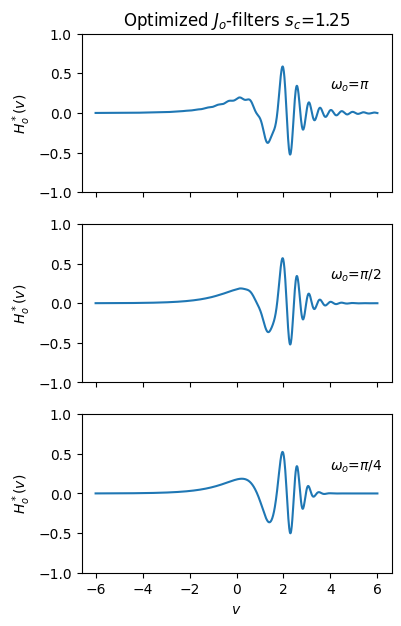

In [4]:
lmda = np.linspace(-6, 6, 1001)
Hnustar = optimized_coefficients_christensen1990(lmda, omega_0=pi/4, smp_per_decade=10)#, -1, 1)

fig,axs = plt.subplots(3,1, sharex=True, sharey=True, figsize=(4,7))

for ax,omega,name in zip(axs, [pi, pi/2, pi/4], ['$\pi$', '$\pi/2$', '$\pi/4$']):
    Hnustar = optimized_coefficients_christensen1990(lmda, omega_0=omega)
    ax.plot(lmda, Hnustar)
    ax.set_ylabel('$H_o^*(v)$')
    ax.text(4, 0.3, f'$\omega_o$={name}')
ax.set_xlabel('$v$')
ax.set_ylim(-1,1)
axs[0].set_title('Optimized $J_o$-filters $s_c$=1.25')

0.3787375415282392
0.3023255813953488


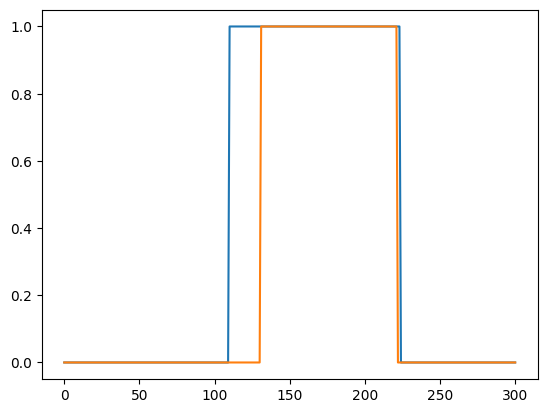

In [5]:
delta = 1/10
vmin = 10**(-200*delta)
vmax = 10**(100*delta)

smp_per_decade=10

v = np.log(10**((np.arange(301)-200)*delta))
mycoef = optimized_coefficients_christensen1990(v, omega_0=np.pi/4, nu=-0.5, smp_per_decade=smp_per_decade) \
        +1j*optimized_coefficients_christensen1990(v, omega_0=np.pi/4, nu=0.5, smp_per_decade=smp_per_decade)

i_sort      = np.argsort(np.abs(mycoef))
i_unsort = np.zeros(len(i_sort), dtype=int)
i_unsort[i_sort] = np.arange(len(i_sort))

cs = np.cumsum(np.abs(mycoef)[i_sort])
cs /= cs.max()
one_percent = (cs>0.00001)
#[unsort]
# one_percent[i_sort][cs<0.01] = False

print(one_percent.sum()/len(one_percent))

plt.figure()
plt.plot(one_percent[i_unsort])

delta = 1/10
vmin = 10**(-200*delta)
vmax = 10**(100*delta)


v = np.log(10**((np.arange(301)-200)*delta))
# mycoef = optimized_coefficients_christensen1990(
#     v, omega_0=np.pi/4, nu=1, convergence_threshold=1e-14)

i_sort      = np.argsort(np.abs(mycoef))
i_unsort = np.zeros(len(i_sort), dtype=int)
i_unsort[i_sort] = np.arange(len(i_sort))

cs = np.cumsum(np.abs(mycoef)[i_sort])
cs /= cs.max()
one_percent = (cs>0.0001)

print(one_percent.sum()/len(one_percent))
plt.plot(one_percent[i_unsort])


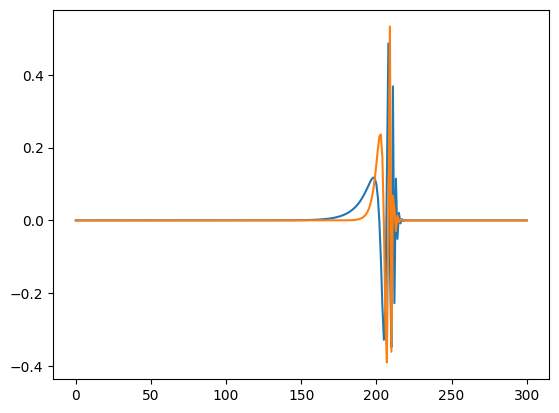

In [6]:
plt.figure()
plt.plot(mycoef.real)
plt.plot(mycoef.imag)

In [7]:
delta = 1/10
vmin = 10**(-200*delta)
vmax = 10**(100*delta)


v = np.log(10**((np.arange(301)-200)*delta))
mycoef = optimized_coefficients_christensen1990(
    v, omega_0=np.pi/4, convergence_threshold=1e-14)

In [8]:
def plot_loglog(x, *args, color='C0', ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    if len(args) > 0:
        t = x
        x = args[0]
    else:
        t = np.arange(len(x))

    if x.dtype == complex:

        xp = x.real*1.
        xn = x.real*1.
        xp[x < 0] = np.nan
        xn[x > 0] = np.nan

        yp = x.imag*1.
        yn = x.imag*1.
        yp[yp < 0] = np.nan
        yn[yp > 0] = np.nan
        ax.loglog(t, xp, 'C0', label='Real')
        ax.loglog(t, np.abs(xn), 'C0--')
        ax.loglog(t, yp, 'C1', label='Imag')
        ax.loglog(t, np.abs(yn), 'C1--')
        ax.legend()
    else:
        xp = x*1.
        xn = x*1.
        xp[x < 0] = np.nan
        xn[x > 0] = np.nan
        ax.loglog(t, xp, color)
        ax.loglog(t, np.abs(xn), color+'--')
    return ax

In [9]:
class Hankel:
    def __init__(self, func, order, log10min=-20, log10max=10, smp_per_decade=10):
        self.func    = func
        self.nu    = order
        self.smp_per_decade = smp_per_decade
        self.n_decades = log10max-log10min
        self.lamda = 10**(np.arange(log10min*smp_per_decade, log10max*smp_per_decade+1)*self.delta)
        self.v     = np.log(self.lamda)
        self.filter_coefficients=self.calc_coefficients()
        self.filter_i0 = np.searchsorted(v, 0)
        self.F = self.func(self.lamda)
    
    @property
    def delta(self):
        return 1./self.smp_per_decade
    
    def calc_coefficients(self):
        return optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4., nu=self.nu)
    
    def __call__(self, r):
        i_offset = int(np.round(self.smp_per_decade*np.log10(r)))
        if i_offset==0:
            return self.F.dot(self.filter_coefficients)/r
        else:
            return self.F[:-i_offset].dot(self.filter_coefficients[i_offset:])/r

        

In [10]:
# @cache
m=1.
def freq_response(omega):
    k = calc_wavenumber(omega, sigma)
    Hz = 9 - (9 + 9j*k*rho - 4*k**2 * rho**2 -
              1j*k**3*rho**3)*np.exp(-1j*k*rho)
    Hz *= m/(2*np.pi*k**2 * rho**5)
    return Hz

In [11]:
from functools import cache

# so lets set this up.
import matplotlib.pyplot as plt
import numpy as np

mu0 = np.pi*4e-7
epsilon0 = 8.854187817e-12

# using values from the example in Fig 4.2
rho = 100.                   # meters
sigma = 1./100.            # 1/ohm-m
frqs = np.logspace(-6, 5, 501)  # Hz
omega = 2*np.pi*frqs           # radians

def calc_rte_halfspace(omega, sigma, wave_length, epsilon=None, mu=None):
    if epsilon is None:
        epsilon = epsilon0*np.ones_like(sigma)
    if mu is None:
        mu = mu0*np.ones_like(sigma)

    lambda_sqrd = wave_length*wave_length
    K1_sqrd = mu*omega*(epsilon*omega-1j*sigma)
    u1 = np.sqrt(lambda_sqrd-K1_sqrd)
    rte = 1./(wave_length+u1)
    return rte


hz = np.zeros(len(frqs), dtype=complex)
for i_frq, freq in enumerate(frqs):
    freq *= 2*np.pi
    def rte1(wave_length):
        return calc_rte_halfspace(freq, sigma, wave_length)*wave_length**3
    Hkl_rte1 = Hankel(rte1, 0)
    hz[i_frq] = Hkl_rte1(100.)
    
hz /= (2*np.pi)

In [12]:
def calc_wavenumber(omega, sigma, mu=mu0, epsilon=epsilon0):
    return np.sqrt(mu*omega*(epsilon*omega - 1j*sigma))
    
def freq_response(omega):
    k = calc_wavenumber(omega, sigma)
    Hz = 9 - (9 + 9j*k*rho - 4*k**2 * rho**2 -
              1j*k**3*rho**3)*np.exp(-1j*k*rho)
    Hz /= (2*np.pi*k**2 * rho**5)
    return Hz  # / (1j*omega)

In [13]:
Hz = freq_response(omega)
np.allclose(hz, Hz)

True

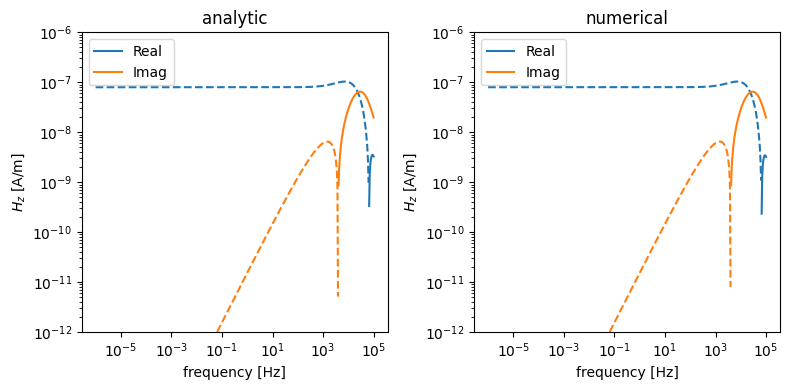

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
ax = plot_loglog(frqs, Hz, ax=axs[0])
ax.set_ylabel('$H_z$ [A/m]')
ax.set_xlabel('frequency [Hz]')
ax.set_ylim(1e-12, 1e-6)
# ax.set_xlim(1e-1, 1e5)
ax.set_title('analytic')


ax = plot_loglog(frqs, hz, ax=axs[1])
ax.set_ylabel('$H_z$ [A/m]')
ax.set_xlabel('frequency [Hz]')
ax.set_ylim(1e-12, 1e-6)
# ax.set_xlim(1e-1, 1e5)
ax.set_title('numerical')
plt.tight_layout()

In [15]:
# instead of giving hz(t) from Hz(f) this is giving d Hz / dt (t)
twopi = np.pi*2.
twopi_sqrt = np.sqrt(2*np.pi)


class Fourier:
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=15):
        self.func = func
        self.smp_per_decade = smp_per_decade
        self.n_decades = log10max-log10min
        self.lamda = 10**(np.arange(log10min*smp_per_decade,
                          log10max*smp_per_decade+1)*self.delta)
        self.v = np.log(self.lamda)
        self.fc = optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=-0.5, smp_per_decade=self.smp_per_decade) \
                  +1j*optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=0.5, smp_per_decade=self.smp_per_decade)
        self.F = self.func(self.lamda)*np.sqrt(self.lamda)

    @property
    def delta(self):
        return 1./self.smp_per_decade

    def __call__(self, r):
        i_offset = int(np.round(self.smp_per_decade*np.log10(r)))
        r_offset = 10**(i_offset*self.delta)
        if i_offset == 0:
            return self.F.dot(self.fc)/np.sqrt(r_offset)/twopi_sqrt
        else:
            return self.F[-i_offset:].dot(self.fc[:i_offset])/np.sqrt(r_offset)/twopi_sqrt

In [84]:
class Fourier:
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=15):
        self.func = func
        self.smp_per_decade = smp_per_decade
        self.n_decades = log10max-log10min
        self.lamda = 10**(np.arange(log10min*smp_per_decade,
                          log10max*smp_per_decade+1)*self.delta)
        self.v = np.log(self.lamda)
        self.fc = optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=-0.5, smp_per_decade=self.smp_per_decade) \
                  +1j*optimized_coefficients_christensen1990(self.v, omega_0=np.pi/4, nu=0.5, smp_per_decade=self.smp_per_decade)
        self.F = self.func(self.lamda)*np.sqrt(self.lamda)

    @property
    def delta(self):
        return 1./self.smp_per_decade

    def __call__(self, r):
        i_offset = int(np.round(self.smp_per_decade*np.log10(r)))
        r_offset = 10**(i_offset*self.delta)
        if i_offset == 0:
            return twopi_sqrt*self.F.dot(self.fc)/np.sqrt(r_offset)
        else:
            return twopi_sqrt*self.F[-i_offset:].dot(self.fc[:i_offset])/np.sqrt(r_offset)
        
    def range(self, tmin, tmax):
        imin = int(np.floor(self.smp_per_decade*np.log10(tmin))-1)
        imax = int(np.ceil(self.smp_per_decade*np.log10(tmax))+1)
        i_offsets = np.arange(imin, imax)
        tout = 10**(i_offsets*self.delta)
        Ht = np.zeros(tout.shape, dtype=complex)
        for i,i_offset in enumerate(i_offsets):
            if i_offset>0:
                Ht[i] = np.einsum('...i,...i->...', self.F[..., :-i_offset], self.fc[..., i_offset:])
            elif i_offset<0:
                i_offset *= -1
                Ht[i] = np.einsum('...i,...i->...', self.fc[..., :-i_offset], self.F[..., i_offset:])
            else:
                Ht[i] = np.einsum('...i,...i->...', self.F, self.fc)
        return tout, twopi_sqrt*Ht/np.sqrt(tout)

In [85]:
a = 1e-2
def f1(x):
    return np.exp(-a*x**2)

def F1(k):
    return np.sqrt(np.pi/a)*np.exp(-np.pi*np.pi*k*k/a)

In [86]:
2*np.pi

6.283185307179586

In [87]:
h1[0]/ht[0]

(0.9999928824434754-0.000483899732049443j)

In [90]:
np.e

2.718281828459045

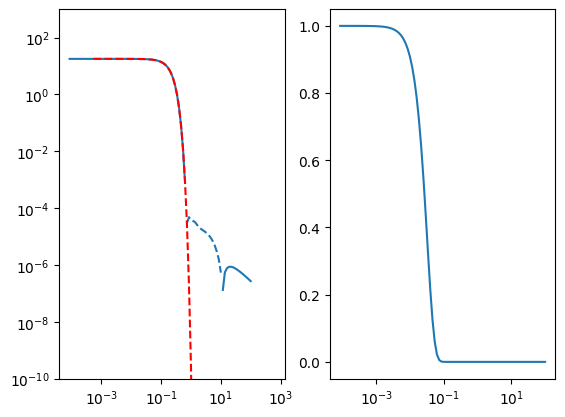

In [95]:
# from em1d.transforms import Fourier

hkl_cos = Fourier(f1)#, log10min=-30, log10max=20, smp_per_decade=20)
ts,ht = hkl_cos.range(1e-4,1e2)

h1 = F1(ts)
# h1 = np.gradient(F1(ts))/np.gradient(ts)

fig,axs = plt.subplots(1,2)
plot_loglog(ts, ht.real, ax=axs[0])
axs[0].loglog(ts*2*np.pi, h1, 'r--')
axs[0].set_ylim(1e-10, 1e3)
# axs[0].set_xlim(1e-2, 1)
axs[1].semilogx(ts, h1/ht.real)

In [316]:
def freq_response(omega):
    k = calc_wavenumber(omega, sigma)
    Hz = 9 - (9 + 9j*k*rho - 4*k**2 * rho**2 -
              1j*k**3*rho**3)*np.exp(-1j*k*rho)
    Hz /= (2*np.pi*k**2 * rho**5)
    return Hz

def f1(x):
    return freq_response(x)#/(1j*x)

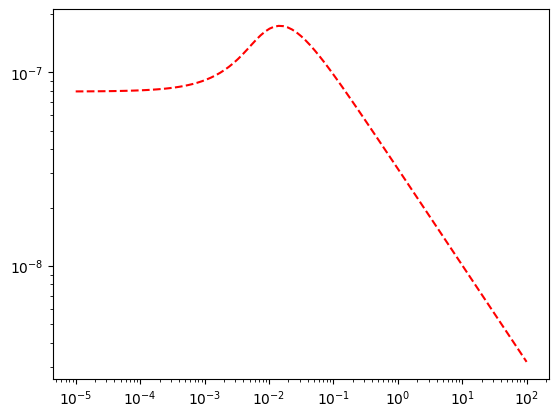

In [317]:
from scipy.special import erf, erfc

hkl_cos = Fourier(f1)
ts = np.logspace(-8, -1, 101)

ht = np.zeros_like(ts, dtype=complex)
for it, t in enumerate(ts):
    ht[it] = hkl_cos(t)


theta = np.sqrt(0.25*mu0*sigma / ts)

thro  = theta*rho
# eq 4.69a
hz = m*((0.5*9*erf(thro)/(thro**2)) - erf(thro) - (1/np.sqrt(pi))*(9/thro + 4*thro)*np.exp(-thro**2))/(4*pi*rho**3)

# eq 4.69
hz = -m*((0.5*9*erf(thro)/(thro**2)) + erf(thro) - (1/np.sqrt(pi))
         * (4*thro+ 9/thro)*np.exp(-thro**2))/(4*pi*rho**3)


ax = plot_loglog(ts*1e3, hz,  color='r')
# ax = plot_loglog(ts*1e3, ht, ax=ax)

In [318]:
from em1d.transforms import Fourier

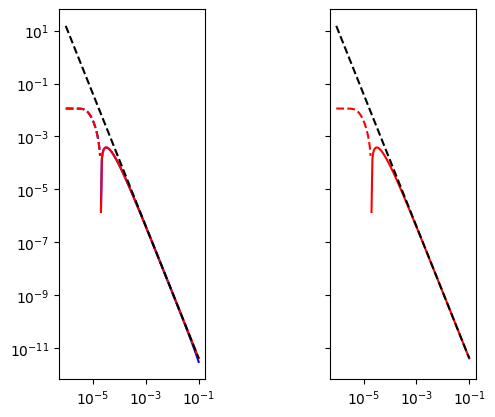

In [319]:
from scipy.special import erf

hkl_cos = Fourier(f1, smp_per_decade=30)
ts = np.logspace(-6, -1, 51)

# ht = np.zeros_like(ts, dtype=complex)
# for it,t in enumerate(ts):
#     ht[it] = hkl_cos(t)
ts,ht = hkl_cos.range(1e-6, 1e-1)

theta = np.sqrt(0.25*mu0*sigma / ts)

hzdt_a = -(m/(2*np.pi*mu0*sigma*rho**5))*(9*erf(theta*rho)-2*theta*rho *
                                          (1/np.sqrt(np.pi))*(9+6*theta**2*rho**2+4*theta**4*rho**4)*np.exp(-theta**2*rho**2))

# assert np.allclose(ht.real, hzdt_a.real), "Fourier transform isn't performing well"

hzdt_approx = -(m/20)*(sigma*mu0/np.pi)**(3/2) * ts**(-5/2)

fig,axs = plt.subplots(1,2, sharex=True, sharey=True)

ax=plot_loglog(ts, ht.real, ax=axs[0], color='b')
plot_loglog(ts, hzdt_a.real, ax=axs[0], color='r')

plot_loglog(ts, hzdt_a, ax=axs[1], color='r')
axs[0].loglog(ts, np.abs(hzdt_approx), 'k--')
axs[1].loglog(ts, np.abs(hzdt_approx), 'k--')
axs[1].set_aspect('equal'); axs[0].set_aspect('equal')

In [320]:
defaultFC_param = {'log10min':-20, 'log10max':10, 'smp_per_decade':10}
#defaultFC_hankel_j0 = optimized_coefficients_christensen1990()

class Hankel:
    def __init__(self, func, order, log10min=-20, log10max=10, smp_per_decade=10):
        pass

In [87]:
print(defaultFC_param.values())
print(Hankel.__init__.__defaults__)

dict_values([-20, 10, 10])
(-20, 10, 10)
